# 17. One-shot multi-coin confirmatory holdout: 2018–2019, ten coins

In notebook 16 (development period), the most elaborate model (GBM) looked best under standard evaluation, but all of its additional hits were detections **after** the onset, while the volatility-based methods (V+F, volatility threshold) also showed warning **before** the onset for 3–4% events. The V+F pre-onset warning, however, disappeared in the BTC holdout (notebook 11). Here I test this exactly once, with hypotheses fixed in advance, on ten altcoins in 2018–2019 whose data I had **never downloaded**.

I follow a four-step procedure.
1. I first freeze the hypotheses, decision rules, coins, period and procedure in `HOLDOUT17_SPEC.json` (SHA-256), with the features, hyperparameters and VPIN settings of the notebook 16 spec.
2. Phase 1: for each coin I train on 2021 and calibrate on 2022 with the notebook 16 procedure and fixed hyperparameters, then freeze the model files and thresholds in `COIN_MODELS_FROZEN.json` (SHA-256).
3. Phase 2: only then do I download the 2017-11 to 2019-12 archives and compute events and alerts, without examining outcomes.
4. Phase 3 (last cell): I examine outcomes for the first time and test the hypotheses.

The coins are ETH, XRP, LTC, BNB, ADA, EOS, TRX, ETC, XLM and NEO (USDT spot). I already used BTC in notebook 11 and read ETH 2020 in notebook 10, so I use only 2018–2019.

I preregistered the following hypotheses (primary definition = 4% scaled by coin volatility; primary methods = V+F, volatility threshold and GBM; pooled over the ten coins):
- H1 in-progress detection: post-onset hits exceed chance. H1 holds if the Holm-adjusted p<0.05 under **both** the regime-matched null and the joint circular-shift null common to all coins.
- H2 pre-onset warning: pre-onset hits exceed chance. H2 holds if the Holm-adjusted p<0.05 under **either** null (I set this rule in favor of predictive skill).
- H3 illusion: the standard evaluation (composite, circular shift) is significant, H1 holds and H2 does not. If this holds for at least two of the three methods, I conclude that "the illusion generalizes out of sample".
- I also report the 95% upper bound of the pre-onset excess and the 95% lower bound of the in-progress excess, since not significant does not mean absent.

This is a confirmatory one-shot holdout: I preregistered it in `HOLDOUT17_SPEC.json` and evaluate it once. I write the results to `HOLDOUT17_multicoin_2018_2019_v1`.

In [4]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier

OUT = SPOT_BASE / 'HOLDOUT17_multicoin_2018_2019_v1'
for _s in ['phase1', 'phase2', 'models']:
    (OUT / _s).mkdir(parents=True, exist_ok=True)
ZIPS = Path('/content/holdout17_zips') if Path('/content').exists() else OUT / 'zips'
COINS = ['ETHUSDT', 'XRPUSDT', 'LTCUSDT', 'BNBUSDT', 'ADAUSDT', 'EOSUSDT', 'TRXUSDT', 'ETCUSDT', 'XLMUSDT', 'NEOUSDT']
TRAIN_MONTHS = month_list('2020-11', '2022-12'); HOLD_MONTHS = month_list('2017-11', '2019-12')
TRAIN_END = pd.Timestamp('2022-12-31 23:59', tz='UTC'); HOLD_LAST = pd.Timestamp('2019-12-31 23:59', tz='UTC')
H_START, H_END = '2018-01-01', '2020-01-01'
DEFS = {'d3': 0.03, 'd4': 0.04, 'd5': 0.05}; PRIMARY_DEF = 'd4'
METHOD_NAMES = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']; PRIMARY = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich']
N_PRIMARY = 5000; N_SECONDARY = 1000; SEED = 20261031; ALPHA = 0.05
MIN_EVAL_DAYS = 180; WARMUP_DAYS = 1
KEYS = ['pre', 'post', 'caught', 'onset_anchored']
LOCK = OUT / 'HOLDOUT17_EVALUATED.lock'
if LOCK.exists():
    raise RuntimeError(f'This holdout has already been evaluated (one-shot): {OUT}. It will not be evaluated again.')

M16 = SPOT_BASE / 'methods_definitions_v1'
spec16 = json.loads((M16 / 'METHODS_SPEC.json').read_text()); summ16 = json.loads((M16 / 'METHODS_SUMMARY.json').read_text())
if summ16['spec_sha256'] != sha256_file(M16 / 'METHODS_SPEC.json'):
    raise RuntimeError('GUARD FAIL: notebook-16 spec hash differs from its summary; finish notebook 16 first')
if spec16['gbm_params'] != json.loads(json.dumps(GBM_PARAMS)) or spec16['gbm_features'] != FEATS or \
        spec16['vpin']['window_buckets'] != VPIN_WINDOW or spec16['definitions'] != {'3pct': 0.03, '4pct': 0.04, '5pct': 0.05}:
    raise RuntimeError('GUARD FAIL: procedure differs from notebook 16')


def daily_sigma_2021(index, close):
    r = pd.Series(np.log(close), index=index).diff()
    d = r.loc['2021'].groupby(r.loc['2021'].index.floor('D')).agg(['std', 'count'])
    return float((d.loc[d['count'] >= 1000, 'std'] * np.sqrt(1440)).median())


_px, _ = load_btc_spot(); SIG_BTC = daily_sigma_2021(_px.index, _px.close.to_numpy(float)); del _px, _

HSPEC = {
    'title': 'One-shot multi-coin confirmatory holdout: detection vs prediction, Binance spot 1m, 2018-01-01 to 2020-01-01 (exclusive)',
    'coins': COINS, 'holdout_window': [H_START, H_END], 'holdout_archives': [HOLD_MONTHS[0], HOLD_MONTHS[-1]],
    'prior_use': 'none of the 2017-11..2019-12 coin-months were downloaded or evaluated before; BTC excluded (used in notebook 11); '
                 'ETH 2020 was read in notebook 10 and is outside this window',
    'per_coin_eval_start': f'max(2018-01-01, first UTC day with finite z_vol and z_hs + {WARMUP_DAYS} day); coin excluded if fewer than {MIN_EVAL_DAYS} evaluation days',
    'procedure': {'source': 'identical to notebook 16 (spec sha256 recorded below)', 'methods': METHOD_NAMES,
                  'training': "coin's own 2021 (minus last 245 min); label = breach of the coin-scaled definition 30-240 min ahead",
                  'calibration': "coin's own 2022, notebook-5 calendar rule; budget per coin 20/month, 240/yr, 240-min cooldown",
                  'models_frozen_before_holdout_download': 'COIN_MODELS_FROZEN.json (sha256) written in phase 1, verified in phase 2',
                  'exclusion': 'a coin-definition with no 2021 training events is excluded for all methods'},
    'definitions': {k: f'{v:.0%} x sigma_coin_2021 / sigma_BTC_2021 (notebook-10 rule)' for k, v in DEFS.items()}, 'sigma_btc_2021': SIG_BTC,
    'endpoints': {'pre': 'matched alert 30-240 min before the breach and before the 1% onset', 'post': 'same window, at or after the onset',
                  'caught': 'pre + post (standard evaluation)', 'onset_anchored': 'alert within 240 min before the onset (secondary)'},
    'pooling': 'sum over coins', 'primary': {'definition': PRIMARY_DEF, 'methods': PRIMARY},
    'nulls': {'regime_matched': f'per coin, each alert moved to a random minute of the same 24h-RV decile within +-{REGIME_WINDOW_D}d, >=240 min away',
              'joint_circular': 'all coins shifted by the same U[7d, Lmin-7d] (circular within each coin window): keeps cross-coin dependence',
              'joint_4h_1d': 'same shift +-U[240,1440] min for all coins (secondary)'},
    'draws': {'primary_regime_and_joint_circular': N_PRIMARY, 'all_other': N_SECONDARY}, 'seed': SEED,
    'hypotheses': {'H1_in_progress_detection': 'pooled post-onset hits exceed the null; supported if Holm(3 methods)-adjusted one-sided p<0.05 under BOTH regime-matched and joint-circular nulls',
                   'H2_early_warning': 'pooled pre-onset hits exceed the null; supported if Holm-adjusted p<0.05 under EITHER null',
                   'H3_illusion': 'per method: composite significant (joint circular, Holm) AND H1 supported AND H2 not supported; '
                                  'generalizes if it holds for at least 2 of the 3 primary methods',
                   'bounds': '95% upper bound of pre-onset excess = observed - 5th percentile of the regime-matched null; 95% lower bound of post-onset excess = observed - 95th percentile'},
    'secondary': 'definitions d3/d5, VPIN, joint 4h-1d null, onset-anchored, per-coin counts: reported without decisions',
    'notebook16': {'spec_sha256': summ16['spec_sha256'], 'frozen_sha256': summ16.get('frozen_sha256')},
    'rules': 'outcomes are computed only in the last cell; reported as observed; a lock file refuses re-evaluation'}
raw_spec = (json.dumps(HSPEC, indent=2, sort_keys=True, default=float) + '\n').encode()
spec_path = OUT / 'HOLDOUT17_SPEC.json'
if spec_path.exists() and spec_path.read_bytes() != raw_spec:
    if any((OUT / 'phase2').iterdir()):
        raise RuntimeError('The spec cannot be changed after reading of the holdout data has started.')
    spec_path.rename(OUT / f'HOLDOUT17_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
    print('Spec change recorded: allowed because no holdout data has been read yet; previous spec archived')
spec_path.write_bytes(raw_spec); SPEC_SHA = hashlib.sha256(raw_spec).hexdigest()
(OUT / 'HOLDOUT17_SPEC.sha256').write_text(SPEC_SHA + '  HOLDOUT17_SPEC.json\n')
print('Spec frozen before any 2018-2019 data is read. SHA-256:', SPEC_SHA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Spec frozen before any 2018-2019 data is read. SHA-256: b1bdcfd9322ab5b18cf56d011f63667436569589b8d40c2cea614d389337875d


## Common functions

In [5]:
def build_block(sym, months, last, man_name):
    man = get_archives('spot', sym, months, ZIPS / sym, allow_missing=True)
    man.to_csv(OUT / man_name, index=False)
    if (man.status != 'not_listed').sum() == 0:
        return man, None, None
    reg = regularize(load_archives(man, ZIPS / sym), end=last).loc[:last]
    base = compute_spot_features(reg)
    return man, reg, causal_features(reg, base)


def valid_mask(reg, F):
    c = reg.close.to_numpy(float); v = reg.volume.to_numpy(float)
    z = F.z_vol.to_numpy(float); f = F.tsr.to_numpy(float); h = F.z_hs.to_numpy(float)
    return np.isfinite(c) & (c > 0) & np.isfinite(v) & (v > 0) & np.isfinite(z) & np.isfinite(f) & np.isfinite(h) & (f >= 0) & (f <= 1)


def score(mname, F, rows, model):
    S = np.full(len(F), np.nan)
    if mname == 'M1_vol_threshold':
        S[rows] = F.z_vol.to_numpy(float)[rows]
    elif mname == 'M2_VPIN':
        S[rows] = F.vpin.to_numpy(float)[rows]
    elif mname == 'M0_VF_logit':
        X = F[['z_vol', 'tsr']].to_numpy(float); ok = rows & np.isfinite(X).all(axis=1)
        S[ok] = model.predict_proba(X[ok])[:, 1]
    else:
        X = F[FEATS].to_numpy(np.float32); S[rows] = model.predict_proba(X[rows])[:, 1]
    return S


def onset_anchored(ev, a):
    used = np.zeros(len(a), bool); n = 0
    for o in np.sort(ev.onset_1pct_utc.astype('int64').to_numpy()):
        l_ = np.searchsorted(a, o - LEAD_MAX * NS, 'left'); r_ = np.searchsorted(a, o, 'left')
        for j in range(l_, r_):
            if not used[j]:
                used[j] = True; n += 1; break
    return n


def counts(ev, a):
    a = np.sort(np.asarray(a, np.int64))
    if len(ev) == 0:
        return dict(pre=0, post=0, caught=0, onset_anchored=0)
    m = match_events(ev, a); pre = int(m.pre1pct.sum()) if len(m) else 0
    return dict(pre=pre, post=len(m) - pre, caught=len(m), onset_anchored=onset_anchored(ev, a))

## Phase 1: per-coin 2021 training, 2022 calibration and model freeze (before any holdout data)

In [6]:
t_all = time.time()
for sym in COINS:
    pf = OUT / 'phase1' / f'{sym}.json'
    if pf.is_file():
        e = json.loads(pf.read_text())
        for c in e['configs'].values():
            if c.get('model_file') and sha256_file(OUT / c['model_file']) != c['model_sha256']:
                raise RuntimeError(f'GUARD FAIL: {sym} model file changed after freezing')
        print(sym, 'phase 1 already frozen'); continue
    t0 = time.time()
    man, reg, F = build_block(sym, TRAIN_MONTHS, TRAIN_END, f'phase1/{sym}_train_manifest.csv')
    if reg is None:
        pf.write_text(json.dumps(dict(symbol=sym, excluded='no 2020-11..2022-12 archives', configs={}))); continue
    T = reg.index.asi8; close = reg.close.to_numpy(float); volume = reg.volume.to_numpy(float)
    VALID = valid_mask(reg, F); tr = train_mask(T, VALID); cal = VALID & in_period(T, '2022-01-01', '2023-01-01')
    sigma = daily_sigma_2021(reg.index, close); scale = sigma / SIG_BTC
    entry = dict(symbol=sym, sigma_2021=sigma, scale_vs_btc=scale, train_rows=int(tr.sum()), cal_rows=int(cal.sum()),
                 manifest_sha256=sha256_file(OUT / f'phase1/{sym}_train_manifest.csv'), configs={}, excluded_definitions={})
    for dname, d in DEFS.items():
        E = price_only_catalog(close, volume, reg.index, decline=d * scale)
        y = label_from_catalog(T, E)
        n21 = int(((E.breach_utc >= ts('2021-01-01')) & (E.breach_utc < ts('2022-01-01'))).sum())
        if y[tr].sum() == 0 or n21 == 0:
            entry['excluded_definitions'][dname] = 'no 2021 training events'; continue
        for mname in METHOD_NAMES:
            model = None; info = {}
            if mname == 'M0_VF_logit':
                X = F[['z_vol', 'tsr']].to_numpy(float); ok = tr & np.isfinite(X).all(axis=1)
                model = new_logit().fit(X[ok], y[ok])
            elif mname == 'M3_GBM_rich':
                model = HistGradientBoostingClassifier(**GBM_PARAMS).fit(F[FEATS].to_numpy(np.float32)[tr], y[tr])
            if model is not None:
                mp = OUT / 'models' / f'{sym}_{mname}_{dname}.joblib'; joblib.dump(model, mp)
                info = dict(model_file=str(mp.relative_to(OUT)), model_sha256=sha256_file(mp))
            S = score(mname, F, cal, model); okc = cal & np.isfinite(S)
            th, ncal, _ = calibrate_calendar(T[okc], S[okc])
            entry['configs'][f'{mname}|{dname}'] = dict(method=mname, definition=dname, decline=d * scale, threshold_2022=th,
                                                        cal_alerts_2022=ncal, train_events_2021=n21, train_positive_minutes=int(y[tr].sum()), **info)
    pf.write_text(json.dumps(entry, indent=2, default=float))
    print(f'{sym}: scale {scale:.2f}, configs {len(entry["configs"])}, excluded {entry["excluded_definitions"]} ({time.time() - t0:.0f}s)')
    del reg, F, T, close, volume, VALID, tr, cal

FROZEN = {s: json.loads((OUT / 'phase1' / f'{s}.json').read_text()) for s in COINS}
raw_f = (json.dumps(FROZEN, indent=2, sort_keys=True, default=float) + '\n').encode()
fz = OUT / 'COIN_MODELS_FROZEN.json'
if fz.exists() and fz.read_bytes() != raw_f:
    raise RuntimeError('GUARD FAIL: frozen coin models differ from an earlier freeze')
fz.write_bytes(raw_f); FROZEN_SHA = hashlib.sha256(raw_f).hexdigest()
(OUT / 'COIN_MODELS_FROZEN.sha256').write_text(FROZEN_SHA + '  COIN_MODELS_FROZEN.json\n')
print(f'Phase 1 frozen ({time.time() - t_all:.0f}s). COIN_MODELS_FROZEN sha256:', FROZEN_SHA)
display(pd.DataFrame([dict(coin=s, scale=e.get('scale_vs_btc'), configs=len(e['configs']), excluded=e.get('excluded_definitions') or e.get('excluded'))
                      for s, e in FROZEN.items()]))

ETHUSDT phase 1 already frozen
XRPUSDT phase 1 already frozen
LTCUSDT phase 1 already frozen
BNBUSDT phase 1 already frozen
ADAUSDT phase 1 already frozen
EOSUSDT phase 1 already frozen
TRXUSDT phase 1 already frozen
ETCUSDT phase 1 already frozen
XLMUSDT phase 1 already frozen
NEOUSDT phase 1 already frozen
Phase 1 frozen (1s). COIN_MODELS_FROZEN sha256: 15ad92add6970be94344562b8d2929a0375e637b50a1e6cd64f74ff471f44eee


,coin,scale,configs,excluded
0,ETHUSDT,1.227462,12,None
1,XRPUSDT,1.492585,12,None
2,LTCUSDT,1.464449,12,None
3,BNBUSDT,1.283195,12,None
4,ADAUSDT,1.514320,12,None
5,EOSUSDT,1.466127,12,None
6,TRXUSDT,1.215767,12,None
7,ETCUSDT,1.579452,12,None
8,XLMUSDT,1.518617,12,None
9,NEOUSDT,1.617282,12,None


## Phase 2: events and alerts from 2018–2019 data (no outcomes yet)

In [7]:
t_all = time.time()
for sym in COINS:
    p2 = OUT / 'phase2' / f'{sym}.npz'; meta_p = OUT / 'phase2' / f'{sym}_meta.json'
    if p2.is_file() and meta_p.is_file():
        if json.loads(meta_p.read_text()).get('frozen_sha256') != FROZEN_SHA:
            raise RuntimeError(f'GUARD FAIL: {sym} phase-2 files were made with different frozen models')
        print(sym, 'phase 2 already done'); continue
    entry = FROZEN[sym]; t0 = time.time()
    if not entry['configs']:
        meta_p.write_text(json.dumps(dict(symbol=sym, excluded='phase 1 excluded', frozen_sha256=FROZEN_SHA))); np.savez_compressed(p2); continue
    man, reg, F = build_block(sym, HOLD_MONTHS, HOLD_LAST, f'phase2/{sym}_holdout_manifest.csv')
    if reg is None:
        meta_p.write_text(json.dumps(dict(symbol=sym, excluded='no holdout archives', frozen_sha256=FROZEN_SHA))); np.savez_compressed(p2); continue
    T = reg.index.asi8; close = reg.close.to_numpy(float); volume = reg.volume.to_numpy(float); VALID = valid_mask(reg, F)
    fv = T[VALID & np.isfinite(F.z_vol.to_numpy(float)) & np.isfinite(F.z_hs.to_numpy(float))]
    ev_start = max(ts(H_START), pd.Timestamp(int(fv[0]), tz='UTC').ceil('D') + pd.Timedelta(days=WARMUP_DAYS)) if len(fv) else ts(H_END)
    days = (ts(H_END) - ev_start).total_seconds() / 86400
    meta = dict(symbol=sym, eval_start=ev_start.strftime('%Y-%m-%d'), eval_days=days, frozen_sha256=FROZEN_SHA,
                manifest_sha256=sha256_file(OUT / f'phase2/{sym}_holdout_manifest.csv'), events={}, alerts={})
    if days < MIN_EVAL_DAYS:
        meta['excluded'] = f'only {days:.0f} evaluation days'; meta_p.write_text(json.dumps(meta, default=str)); np.savez_compressed(p2); continue
    rowsE = VALID & (T >= ev_start.value) & (T < ts(H_END).value)
    arrays = {}
    for dname, d in DEFS.items():
        if dname in entry['excluded_definitions']:
            continue
        E = price_only_catalog(close, volume, reg.index, decline=d * entry['scale_vs_btc'])
        for c_ in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
            E[c_] = pd.to_datetime(E[c_], utc=True)
        EV = events_between(E, ev_start.strftime('%Y-%m-%d'), H_END)
        EV.to_csv(OUT / 'phase2' / f'{sym}_{dname}_events.csv', index=False); meta['events'][dname] = len(EV)
        for mname in METHOD_NAMES:
            c = entry['configs'][f'{mname}|{dname}']; model = None
            if c.get('model_file'):
                if sha256_file(OUT / c['model_file']) != c['model_sha256']:
                    raise RuntimeError(f'GUARD FAIL: {sym} {mname} {dname} model hash differs from the freeze')
                model = joblib.load(OUT / c['model_file'])
            S = score(mname, F, rowsE, model); ok = rowsE & np.isfinite(S)
            a = emit_calendar_fast(T[ok], S[ok] >= c['threshold_2022'])
            arrays[f'A|{mname}|{dname}'] = a; meta['alerts'][f'{mname}|{dname}'] = len(a)
    rv = pd.Series(np.log(close)).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
    okr = (T >= ev_start.value) & (T < ts(H_END).value) & np.isfinite(rv)
    arrays['TT'] = T[okr]; arrays['DD'] = np.minimum((pd.Series(rv[okr]).rank(pct=True).to_numpy() * 10).astype(int), 9).astype(np.int8)
    np.savez_compressed(p2, **arrays); meta_p.write_text(json.dumps(meta, indent=2, default=str))
    print(f'{sym}: evaluation from {ev_start.date()} ({days:.0f} days), events {meta["events"]} ({time.time() - t0:.0f}s)')
    del reg, F, T, close, volume, VALID
print(f'Phase 2 done in {time.time() - t_all:.0f}s. Outcomes have not been computed yet.')

ETHUSDT spot {'downloaded': 26}
FFT computation 100,031/1,139,040
FFT computation 1,139,040/1,139,040
ETHUSDT: evaluation from 2018-01-01 (730 days), events {'d3': 236, 'd4': 151, 'd5': 99} (154s)
XRPUSDT spot {'downloaded': 20, 'not_listed': 6}
FFT computation 100,031/873,589
FFT computation 873,589/873,589
XRPUSDT: evaluation from 2018-05-21 (590 days), events {'d3': 105, 'd4': 65, 'd5': 36} (114s)
LTCUSDT spot {'downloaded': 25, 'not_listed': 1}
FFT computation 100,031/1,078,348
FFT computation 1,078,348/1,078,348
LTCUSDT: evaluation from 2018-01-01 (730 days), events {'d3': 169, 'd4': 102, 'd5': 59} (152s)
BNBUSDT spot {'downloaded': 26}
FFT computation 100,031/1,131,606
FFT computation 1,131,606/1,131,606
BNBUSDT: evaluation from 2018-01-01 (730 days), events {'d3': 230, 'd4': 151, 'd5': 100} (149s)
ADAUSDT spot {'downloaded': 21, 'not_listed': 5}
FFT computation 100,031/898,318
FFT computation 898,318/898,318
ADAUSDT: evaluation from 2018-05-04 (607 days), events {'d3': 116, 'd4'

## Phase 3: tests of the preregistered hypotheses (first look at outcomes)

coins evaluated: ['ETHUSDT', 'XRPUSDT', 'LTCUSDT', 'BNBUSDT', 'ADAUSDT', 'EOSUSDT', 'TRXUSDT', 'ETCUSDT', 'XLMUSDT', 'NEOUSDT'] | excluded: []
nulls done in 3252s


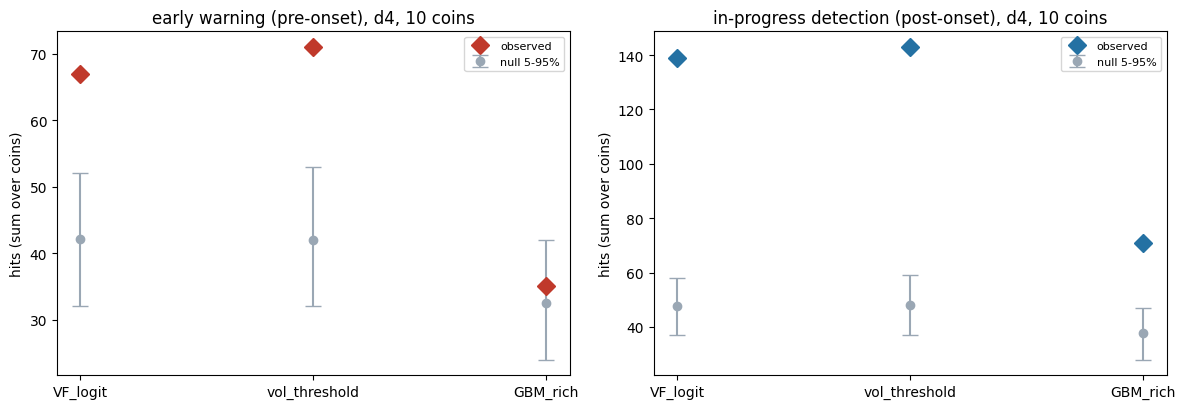

PRIMARY DECISIONS


,method,events,alerts,composite,composite_p_holm_joint,pre,pre_null_mean_regime,pre_p_holm_regime,pre_p_holm_joint,pre_excess_upper95,post,post_null_mean_regime,post_p_holm_regime,post_p_holm_joint,post_excess_lower95,H1_supported,H2_supported,H3_illusion
0,M0_VF_logit,943,4101,206,0.0006,67,42.0792,0.0006,0.0012,35.0,139,47.7264,0.0006,0.0006,81.0,True,True,False
1,M1_vol_threshold,943,4065,214,0.0006,71,41.9282,0.0006,0.0012,39.0,143,48.0218,0.0006,0.0006,84.0,True,True,False
2,M3_GBM_rich,943,3260,106,0.0006,35,32.5012,0.3497,0.3689,11.0,71,37.6758,0.0006,0.0006,24.0,True,False,True


illusion holds for 1 of 3 primary methods -> does not generalize

Per coin (primary definition):


,coin,method,definition,eval_start,events,alerts,pre,post,caught,onset_anchored
0,ETHUSDT,M0_VF_logit,d4,2018-01-01,151,474,7,17,24,16
1,ETHUSDT,M1_vol_threshold,d4,2018-01-01,151,463,8,20,28,15
2,ETHUSDT,M2_VPIN,d4,2018-01-01,151,480,7,6,13,11
3,ETHUSDT,M3_GBM_rich,d4,2018-01-01,151,415,2,11,13,8
4,XRPUSDT,M0_VF_logit,d4,2018-05-21,65,386,9,10,19,11
5,XRPUSDT,M1_vol_threshold,d4,2018-05-21,65,386,9,10,19,11
6,XRPUSDT,M2_VPIN,d4,2018-05-21,65,380,2,1,3,3
7,XRPUSDT,M3_GBM_rich,d4,2018-05-21,65,241,5,13,18,10
8,LTCUSDT,M0_VF_logit,d4,2018-01-01,102,464,5,23,28,12
9,LTCUSDT,M1_vol_threshold,d4,2018-01-01,102,474,6,23,29,12



Secondary (regime-matched null):


endpoint                     caught  onset_anchored    post    pre
definition method                                                 
d3         M0_VF_logit        0.001          0.0040  0.0010  0.007
           M1_vol_threshold   0.001          0.0020  0.0010  0.001
           M2_VPIN            1.000          0.9980  0.9231  0.999
           M3_GBM_rich        0.001          0.0020  0.0010  0.002
d4         M2_VPIN            1.000          1.0000  0.9800  0.999
d5         M0_VF_logit        0.001          0.0110  0.0010  0.001
           M1_vol_threshold   0.001          0.0010  0.0010  0.001
           M2_VPIN            1.000          1.0000  0.9740  1.000
           M3_GBM_rich        0.001          0.2677  0.0010  0.038


Locked: results reported as observed.


In [8]:
def holm(ps):
    ps = np.asarray(ps, float); order = np.argsort(ps); m = len(ps); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, min(1.0, (m - r) * ps[i])); adj[i] = run
    return adj


DATA = {}
for sym in COINS:
    meta = json.loads((OUT / 'phase2' / f'{sym}_meta.json').read_text())
    if meta.get('excluded'):
        continue
    z = np.load(OUT / 'phase2' / f'{sym}.npz')
    evs = {}
    for dname in DEFS:
        p = OUT / 'phase2' / f'{sym}_{dname}_events.csv'
        if p.is_file():
            e = pd.read_csv(p)
            for c_ in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
                e[c_] = pd.to_datetime(e[c_], utc=True)
            evs[dname] = e
    t0 = ts(meta['eval_start']).value
    TT = z['TT']; DD = z['DD'].astype(int); order = np.lexsort((TT, DD))
    DATA[sym] = dict(meta=meta, ev=evs, A={k[2:]: z[k] for k in z.files if k.startswith('A|')}, t0=t0, L=(ts(H_END).value - t0) // NS,
                     TT=TT, DD=DD, P=TT[order], DS=DD[order],
                     starts=np.searchsorted(DD[order], np.arange(10), 'left'), ends=np.searchsorted(DD[order], np.arange(10), 'right'))
USED = list(DATA); LMIN = min(d['L'] for d in DATA.values())
print('coins evaluated:', USED, '| excluded:', [s for s in COINS if s not in DATA])


def pooled(mname, dname, shifted=None):
    tot = dict.fromkeys(KEYS, 0)
    for s, d in DATA.items():
        if dname not in d['ev'] or f'{mname}|{dname}' not in d['A']:
            continue
        a = d['A'][f'{mname}|{dname}'] if shifted is None else shifted.get(s, d['A'][f'{mname}|{dname}'])
        c = counts(d['ev'][dname], a)
        for k in KEYS:
            tot[k] += c[k]
    return tot


def joint_null(mname, dname, n, seed, band=None):
    rng = np.random.default_rng(seed)
    if band is None:
        deltas = rng.integers(7 * 1440, LMIN - 7 * 1440, size=n)
    else:
        deltas = rng.integers(band[0], band[1] + 1, size=n) * (rng.integers(0, 2, size=n) * 2 - 1)
    out = {k: np.empty(n, int) for k in KEYS}
    for i, dl in enumerate(deltas):
        sh = {s: np.sort(d['t0'] + (d['A'][f'{mname}|{dname}'] - d['t0'] + int(dl) * NS) % (d['L'] * NS))
              for s, d in DATA.items() if f'{mname}|{dname}' in d['A']}
        c = pooled(mname, dname, sh)
        for k in KEYS:
            out[k][i] = c[k]
    return out


def regime_null(mname, dname, n, seed):
    rng = np.random.default_rng(seed); W = REGIME_WINDOW_D * 1440 * NS; prep = {}
    for s, d in DATA.items():
        a = d['A'].get(f'{mname}|{dname}')
        if a is None or len(a) == 0:
            continue
        j = np.clip(np.searchsorted(d['TT'], a, 'right') - 1, 0, len(d['TT']) - 1); q = d['DD'][j]
        lo = np.array([d['starts'][x] + np.searchsorted(d['P'][d['starts'][x]:d['ends'][x]], ti - W, 'left') for ti, x in zip(a, q)])
        hi = np.array([d['starts'][x] + np.searchsorted(d['P'][d['starts'][x]:d['ends'][x]], ti + W, 'right') for ti, x in zip(a, q)])
        prep[s] = (a, lo, hi)
    out = {k: np.empty(n, int) for k in KEYS}
    for i in range(n):
        sh = {}
        for s, (a, lo, hi) in prep.items():
            P = DATA[s]['P']; c = P[lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
            for _ in range(20):
                if not bad.any():
                    break
                c[bad] = P[lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
            sh[s] = np.sort(c)
        cc = pooled(mname, dname, sh)
        for k in KEYS:
            out[k][i] = cc[k]
    return out


t_ = time.time(); rows = []; NULLS = {}
for ci, mname in enumerate(METHOD_NAMES):
    for di, dname in enumerate(DEFS):
        prim = (mname in PRIMARY and dname == PRIMARY_DEF)
        n_main = N_PRIMARY if prim else N_SECONDARY
        obs = pooled(mname, dname)
        nl = {'regime-matched': regime_null(mname, dname, n_main, SEED + 100 * ci + 10 * di + 1),
              'joint circular': joint_null(mname, dname, n_main, SEED + 100 * ci + 10 * di + 2),
              'joint 4h-1d': joint_null(mname, dname, N_SECONDARY, SEED + 100 * ci + 10 * di + 3, band=(240, 1440))}
        NULLS[(mname, dname)] = nl
        n_ev = sum(len(d['ev'][dname]) for d in DATA.values() if dname in d['ev'])
        n_al = sum(len(d['A'][f'{mname}|{dname}']) for d in DATA.values() if f'{mname}|{dname}' in d['A'])
        for nname, x in nl.items():
            for k in KEYS:
                rows.append(dict(method=mname, definition=dname, primary=prim, null=nname, endpoint=k, events=n_ev, alerts=n_al,
                                 observed=obs[k], null_mean=float(x[k].mean()), null_q05=float(np.percentile(x[k], 5)),
                                 null_q95=float(np.percentile(x[k], 95)), p_one_sided=(1 + int((x[k] >= obs[k]).sum())) / (len(x[k]) + 1), draws=len(x[k])))
R = pd.DataFrame(rows); R.to_csv(OUT / 'H17_all_tests.csv', index=False)
print(f'nulls done in {time.time() - t_:.0f}s')

P = R[R.primary]


def pv(m, null, ep):
    return float(P[(P.method == m) & (P['null'] == null) & (P.endpoint == ep)].p_one_sided.iloc[0])


dec = []
adj = {(null, ep): dict(zip(PRIMARY, holm([pv(m, null, ep) for m in PRIMARY])))
       for null in ['regime-matched', 'joint circular'] for ep in ['pre', 'post', 'caught']}
for m in PRIMARY:
    r_pre = P[(P.method == m) & (P['null'] == 'regime-matched') & (P.endpoint == 'pre')].iloc[0]
    r_post = P[(P.method == m) & (P['null'] == 'regime-matched') & (P.endpoint == 'post')].iloc[0]
    h1 = adj[('regime-matched', 'post')][m] < ALPHA and adj[('joint circular', 'post')][m] < ALPHA
    h2 = adj[('regime-matched', 'pre')][m] < ALPHA or adj[('joint circular', 'pre')][m] < ALPHA
    comp = adj[('joint circular', 'caught')][m] < ALPHA
    dec.append(dict(method=m, events=int(r_pre.events), alerts=int(r_pre.alerts),
                    composite=int(P[(P.method == m) & (P.endpoint == 'caught')].observed.iloc[0]), composite_p_holm_joint=adj[('joint circular', 'caught')][m],
                    pre=int(r_pre.observed), pre_null_mean_regime=r_pre.null_mean, pre_p_holm_regime=adj[('regime-matched', 'pre')][m],
                    pre_p_holm_joint=adj[('joint circular', 'pre')][m], pre_excess_upper95=float(r_pre.observed - r_pre.null_q05),
                    post=int(r_post.observed), post_null_mean_regime=r_post.null_mean, post_p_holm_regime=adj[('regime-matched', 'post')][m],
                    post_p_holm_joint=adj[('joint circular', 'post')][m], post_excess_lower95=float(r_post.observed - r_post.null_q95),
                    H1_supported=bool(h1), H2_supported=bool(h2), H3_illusion=bool(comp and h1 and not h2)))
D = pd.DataFrame(dec); D.to_csv(OUT / 'H17_primary_decisions.csv', index=False)
per_coin = []
for s, d in DATA.items():
    for (mname, dname) in [(m, PRIMARY_DEF) for m in METHOD_NAMES]:
        if dname in d['ev'] and f'{mname}|{dname}' in d['A']:
            per_coin.append(dict(coin=s, method=mname, definition=dname, eval_start=d['meta']['eval_start'], events=len(d['ev'][dname]),
                                 alerts=len(d['A'][f'{mname}|{dname}']), **counts(d['ev'][dname], d['A'][f'{mname}|{dname}'])))
PC = pd.DataFrame(per_coin); PC.to_csv(OUT / 'H17_per_coin_counts.csv', index=False)

summary = dict(spec_sha256=SPEC_SHA, frozen_sha256=FROZEN_SHA, coins_evaluated=USED, coins_excluded=[s for s in COINS if s not in DATA],
               primary_decisions=D.to_dict('records'), H3_illusion_methods=int(D.H3_illusion.sum()),
               illusion_generalizes=bool(D.H3_illusion.sum() >= 2),
               secondary=R[~R.primary & (R['null'] == 'regime-matched') & R.endpoint.isin(['pre', 'post', 'caught'])]
               [['method', 'definition', 'endpoint', 'observed', 'null_mean', 'p_one_sided']].to_dict('records'))
(OUT / 'HOLDOUT17_RESULTS.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
LOCK.write_text(json.dumps(dict(evaluated_utc=pd.Timestamp.now(tz='UTC').isoformat(), spec_sha256=SPEC_SHA, frozen_sha256=FROZEN_SHA)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for i, ep in enumerate(['pre', 'post']):
    for j, m in enumerate(PRIMARY):
        r = P[(P.method == m) & (P['null'] == 'regime-matched') & (P.endpoint == ep)].iloc[0]
        ax[i].errorbar(j, r.null_mean, yerr=[[r.null_mean - r.null_q05], [r.null_q95 - r.null_mean]], fmt='o', color='#9aa7b4', capsize=6, label='null 5-95%' if j == 0 else None)
        ax[i].plot(j, r.observed, 'D', color='#c0392b' if ep == 'pre' else '#2471a3', ms=9, label='observed' if j == 0 else None)
    ax[i].set_xticks(range(len(PRIMARY))); ax[i].set_xticklabels([m.split('_', 1)[1] for m in PRIMARY])
    ax[i].set_title(f"{'early warning (pre-onset)' if ep == 'pre' else 'in-progress detection (post-onset)'}, {PRIMARY_DEF}, {len(USED)} coins")
    ax[i].set_ylabel('hits (sum over coins)'); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / 'H17_primary.png', dpi=140); plt.show()
print('PRIMARY DECISIONS'); display(D.round(4))
print('illusion holds for', int(D.H3_illusion.sum()), 'of 3 primary methods ->', 'GENERALIZES' if summary['illusion_generalizes'] else 'does not generalize')
print('\nPer coin (primary definition):'); display(PC)
print('\nSecondary (regime-matched null):'); display(R[~R.primary & (R['null'] == 'regime-matched')].pivot_table(index=['definition', 'method'], columns='endpoint', values='p_one_sided').round(4))
print('\nLocked: results reported as observed.')